# Analysis and Geospatial Visualisation

In [ ]:
import math
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window

warnings.filterwarnings("ignore", message="PySpark does not yet fully support pandas")

spark = (
    SparkSession.builder.appName("Airport Trip Analysis")
    .config("spark.sql.session.timeZone", "America/New_York")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")

In [ ]:
CURRENT_DIR = Path.cwd().resolve()

if CURRENT_DIR.name in {"code", "notebooks"}:
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PLOTS_DIR = PROJECT_ROOT / "plots"
TABLES_DIR = PROJECT_ROOT / "tables"

FINAL_DATA_PATH = (PROCESSED_DIR / "airport_weather_trips_2024_h1")

ZONE_MAP_PATH = (PROJECT_ROOT / "data"/ "taxi_zones" / "taxi_zones" / "taxi_zones.shp")

PLOTS_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

BIN_WIDTH = 2

MIN_ZONE_TRIPS = 1000
MAP_CMAP = "magma_r"
MIN_CELL_TRIPS = 50

plot_styles = {
    "JFK Airport": {"color": "#3B528B", "linestyle": "-", "zone_id": 132},
    "LaGuardia Airport": {"color": "#B65C7A", "linestyle": "--", "zone_id": 138}
}

In [ ]:
analysis_data = spark.read.parquet(str(FINAL_DATA_PATH))

analysis_trip_count = analysis_data.count()
analysis_variable_count = len(analysis_data.columns)

print(
    f"Analysis dataset: "
    f"{analysis_trip_count:,} rows x {analysis_variable_count} columns"
)

## Travel-Time Distribution

In [ ]:
duration_summary = (
    analysis_data
    .rollup("airport")
    .agg(
        F.count("*").alias("trip_count"),
        F.round( F.avg("trip_duration_minutes"), 2).alias("mean_minutes"),
        F.round(F.expr("percentile_approx(trip_duration_minutes, 0.50)"), 2).alias("median_minutes"),
        F.round(F.expr("percentile_approx(trip_duration_minutes, 0.95)"), 2).alias("p95_minutes")
    )
    .withColumn("airport", F.coalesce(F.col("airport"), F.lit("Overall")))
    .withColumn("buffer_minutes", F.round(F.col("p95_minutes") - F.col("median_minutes"), 2))
    .orderBy(
        F.when(F.col("airport") == "Overall", 0).when(F.col("airport") == "JFK Airport", 1)
        .otherwise(2)
    )
)

duration_table = duration_summary.toPandas()

duration_table.to_latex(
    buf=TABLES_DIR / "travel_time_summary.tex",
    index=False,
    header=["Airport", "Trips", "Mean", "Median", "P95", "Buffer"],
    column_format="lrrrr",
    float_format="%.2f",
    caption="Summary of airport travel times in minutes.",
    label="tab:travel-time-summary"
)

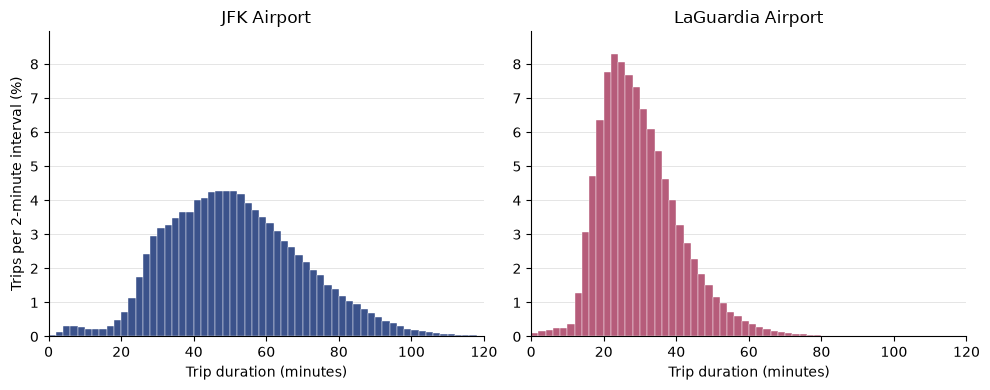

In [ ]:
duration_plot_data = (
    analysis_data
    .withColumn("duration_bin_start",
                F.floor(F.col("trip_duration_minutes") / BIN_WIDTH) * BIN_WIDTH)
    .groupBy("airport", "duration_bin_start")
    .agg(F.count("*").alias("trip_count"))
    .withColumn("airport_total", F.sum("trip_count").over(Window.partitionBy("airport")))
    .withColumn("trip_percentage", F.col("trip_count") / F.col("airport_total") * 100)
    .orderBy("airport", "duration_bin_start")
)

duration_plot_pdf = duration_plot_data.toPandas()

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)

for axis, (airport, style) in zip(axes, plot_styles.items()):
    airport_data = (
        duration_plot_pdf
        .loc[duration_plot_pdf["airport"] == airport]
        .sort_values("duration_bin_start")
    )

    axis.bar(
        airport_data["duration_bin_start"],
        airport_data["trip_percentage"],
        width=BIN_WIDTH,
        align="edge",
        color=style["color"],
        edgecolor="white",
        linewidth=0.3
    )

    axis.set_title(airport)
    axis.set_xlim(0, 120)
    axis.set_xlabel("Trip duration (minutes)")
    axis.set_axisbelow(True)
    axis.grid(axis="y", color="#E5E5E5", linewidth=0.7)
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)
    axis.tick_params(axis="y", labelleft=True)
    
y_max = duration_plot_pdf["trip_percentage"].max() * 1.08
axes[0].set_ylim(0, y_max)

axes[0].set_ylabel(f"Trips per {BIN_WIDTH}-minute interval (%)")
fig.tight_layout()

fig.savefig(PLOTS_DIR / "duration_distribution_by_airport.pdf", bbox_inches="tight")

plt.show()

## Travel Time by Departure Hour

In [ ]:
hourly_duration_summary = (
    analysis_data
    .groupBy("airport", "pickup_hour")
    .agg(F.count("*").alias("trip_count"),
         F.percentile_approx("trip_duration_minutes", 0.5, 10000).alias("median_minutes"),
         F.percentile_approx("trip_duration_minutes", 0.95, 10000).alias("p95_minutes")
    )
    .withColumn("median_minutes", F.round("median_minutes", 2))
    .withColumn("p95_minutes", F.round("p95_minutes", 2))
    .orderBy("airport", "pickup_hour")
)

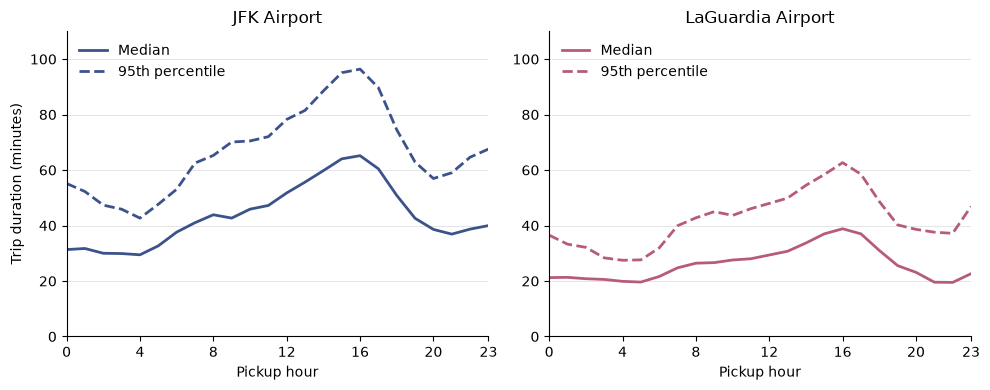

In [ ]:
hourly_plot_data = hourly_duration_summary.toPandas()

fig, axes = plt.subplots(1, 2, figsize=(10,4), sharey=True)

for axis, (airport, style) in zip(axes, plot_styles.items()):
    airport_data = (hourly_plot_data
                    .loc[hourly_plot_data["airport"] == airport]
                    .sort_values("pickup_hour")
    )
    axis.plot(
        airport_data["pickup_hour"],
        airport_data["median_minutes"],
        color = style["color"],
        linewidth=2,
        linestyle="-",
        label="Median"
    )
    axis.plot(
        airport_data["pickup_hour"],
        airport_data["p95_minutes"],
        color = style["color"],
        linewidth=2,
        linestyle="--",
        label="95th percentile"
    )

    axis.set_title(airport)
    axis.set_xlabel("Pickup hour")
    axis.set_xlim(0, 23)
    axis.set_xticks([0, 4, 8, 12, 16, 20, 23])
    axis.set_ylim(0, 110)
    axis.set_axisbelow(True)
    axis.grid(axis="y", color="#E5E5E5", linewidth=0.7)
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)
    axis.tick_params(axis="y", labelleft=True)
    axis.legend(frameon=False, loc="upper left")

axes[0].set_ylabel("Trip duration (minutes)")
fig.tight_layout()

fig.savefig(PLOTS_DIR / "travel_time_by_departure_hour.pdf", bbox_inches="tight")

plt.show()

## Travel Time by Pickup Zone

In [ ]:
zone_duration_summary = (
    analysis_data
    .groupBy("airport","PULocationID", "pickup_borough","pickup_zone")
    .agg(F.count("*").alias("trip_count"),
         F.round(F.percentile_approx("trip_duration_minutes", 0.5, 10000), 2).alias("median_minutes"),
         F.round(F.percentile_approx("trip_duration_minutes", 0.95, 10000), 2).alias("p95_minutes")
    )
    .withColumn("buffer_minutes", F.round(F.col("p95_minutes") - F.col("median_minutes"), 2))
)

In [ ]:
taxi_zone_geo = gpd.read_file(ZONE_MAP_PATH)
taxi_zone_geo = taxi_zone_geo.loc[taxi_zone_geo["borough"].str.strip() != "Staten Island"].copy()

zone_plot_data = zone_duration_summary.toPandas()

zone_maps = {}

for airport in plot_styles:
    airport_summary = zone_plot_data.loc[zone_plot_data["airport"] == airport]

    zone_maps[airport] = taxi_zone_geo.merge(
        airport_summary,
        left_on="LocationID",
        right_on="PULocationID",
        how="left",
        validate="many_to_one"
    )

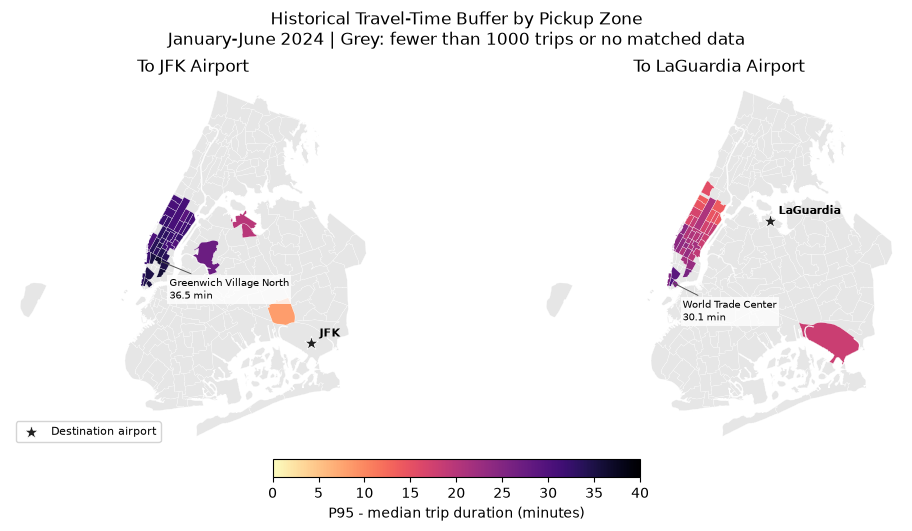

In [ ]:
map_max_raw = max(
    data.loc[data["trip_count"] >= MIN_ZONE_TRIPS, "buffer_minutes"].max()
    for data in zone_maps.values()
)

map_max = math.ceil(map_max_raw / 5) * 5

norm = Normalize(vmin=0, vmax=map_max)
cmap = plt.get_cmap(MAP_CMAP)

display_zones = taxi_zone_geo

xmin,ymin, xmax, ymax = display_zones.total_bounds
x_padding = (xmax - xmin) * 0.03
y_padding = (ymax - ymin) * 0.03

fig, axes = plt.subplots(1, 2, figsize=(10.5, 5.2), layout="constrained")

for axis, (airport, style) in zip(axes, plot_styles.items()):
    map_data = zone_maps[airport]

    eligible_mask = ((map_data["trip_count"] >= MIN_ZONE_TRIPS) &
                     (map_data["pickup_borough"] != "Unknown"))
    
    map_data.plot(
        ax=axis,
        color="#E6E6E6",
        edgecolor="white",
        linewidth=0.2
    )

    map_data.loc[eligible_mask].plot(
        column="buffer_minutes",
        ax=axis,
        cmap=cmap,
        norm=norm,
        edgecolor="white",
        linewidth=0.2
    )

    airport_point = (
        taxi_zone_geo.loc[taxi_zone_geo["LocationID"] == style["zone_id"], "geometry"]
        .representative_point()
        .iloc[0]
    )

    axis.scatter(
        airport_point.x,
        airport_point.y,
        marker="*",
        s=110,
        color="#222222",
        edgecolor="white",
        linewidth=0.6,
        zorder=5,
        label="Destination airport"
    )

    axis.annotate(
        airport.replace("Airport", ""),
        xy=(airport_point.x, airport_point.y),
        xytext=(6,5),
        textcoords = "offset points",
        fontsize=8,
        fontweight="bold"
    )
    
    highlight_zone = (map_data.loc[eligible_mask].nlargest(1, "buffer_minutes").iloc[0])

    highlight_point = (highlight_zone["geometry"].representative_point())
    
    axis.annotate(
        f"{highlight_zone['pickup_zone']}\n"
        f"{highlight_zone['buffer_minutes']:.1f} min",
        xy=(highlight_point.x, highlight_point.y),
        xytext=(8, -12),
        textcoords="offset points",
        fontsize=7.5,
        ha="left",
        va="top",
        arrowprops={
            "arrowstyle": "-",
            "color": "#555555",
            "linewidth": 0.7
        },
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.8,
            "pad": 1.5
        },
        zorder=6
    )

    axis.set_xlim(xmin - x_padding, xmax + x_padding)

    axis.set_ylim(ymin - y_padding, ymax + y_padding)

    axis.set_title(f"To {airport}")
    axis.set_axis_off()

axes[0].legend(
    loc="lower left",
    frameon=True,
    facecolor="white",
    edgecolor="#D0D0D0",
    framealpha=0.9,
    fontsize=8
)

fig.suptitle(
    "Historical Travel-Time Buffer by Pickup Zone\n"
    f"January-June 2024 | Grey: fewer than "
    f"{MIN_ZONE_TRIPS} trips or no matched data",
    fontsize=12
)

fig.colorbar(
    ScalarMappable(norm=norm, cmap=cmap),
    ax=axes.tolist(),
    orientation="horizontal",
    fraction=0.05,
    pad=0.03,
    ticks=range(0, int(map_max) + 1, 5),
    label="P95 - median trip duration (minutes)"
)

fig.savefig(PLOTS_DIR / "pickup_zone_buffer_map.pdf", bbox_inches="tight")

plt.show()

## Weather and Departure-Time Effects

In [ ]:
analysis_weather = (
    analysis_data
    .withColumn("snow_event_for_analysis",
        F.when(F.col("present_weather").isNull(),
            F.lit(None).cast("int"))
        .otherwise(F.col("snow_event")))
)

In [ ]:
time_period_order = [
    "00-03", "04-07", "08-11",
    "12-15", "16-19", "20-23"
]
weather_time_data = (
    analysis_data
    .withColumn("time_period",
                F.when(F.col("pickup_hour") < 4, "00-03")
                .when(F.col("pickup_hour") < 8, "04-07")
                .when(F.col("pickup_hour") < 12, "08-11")
                .when(F.col("pickup_hour") < 16, "12-15")
                .when(F.col("pickup_hour") < 20, "16-19")
                .otherwise("20-23"))
    .withColumn("weather_conditions",
                F.array(
                    F.struct(F.lit("No precipitation").alias("weather_condition"),
                            ((F.col("precipitation_event") == 0) &
                                (F.col("precipitation_missing") == 0)).alias("included")
                        ),
                    F.struct(F.lit("Precipitation").alias("weather_condition"),
                            (F.col("precipitation_event") == 1).alias("included")),
                    F.struct(F.lit("Snow").alias("weather_condition"),
                            (F.col("snow_event") == 1).alias("included")),
                    F.struct(F.lit("Fog / low visibility").alias("weather_condition"),
                            (F.col("fog_or_low_visibility") == 1).alias("included")),
                    F.struct(F.lit("High wind").alias("weather_condition"),
                            (F.col("wind_speed_mph") >= 15).alias("included")),
                    F.struct(F.lit("High humidity").alias("weather_condition"),
                            (F.col("relative_humidity") >= 80).alias("included"))
                ))
    .withColumn("weather_condition_record", F.explode("weather_conditions"))
    .filter(F.col("weather_condition_record.included"))
    .withColumn("weather_condition", F.col("weather_condition_record.weather_condition"))
)

weather_time_summary = (weather_time_data
    .groupBy("airport", "weather_condition", "time_period")
    .agg(
        F.count("*").alias("trip_count"),
        F.percentile_approx("trip_duration_minutes", 0.5, 10000).alias("median_minutes"),
        F.percentile_approx("trip_duration_minutes", 0.95, 10000).alias("p95_minutes")
    )
    .withColumn("buffer_minutes",F.round(F.col("p95_minutes") - F.col("median_minutes"), 2))
    .withColumn("time_order",
        F.when(F.col("time_period") == "00-03", 0)
        .when(F.col("time_period") == "04-07", 1)
        .when(F.col("time_period") == "08-11", 2)
        .when(F.col("time_period") == "12-15", 3)
        .when(F.col("time_period") == "16-19", 4)
        .otherwise(5))
    .withColumn("weather_order", 
                F.when(F.col("weather_condition") == "No precipitation", 0)
                .when(F.col("weather_condition") == "precipitation", 1)
                .when(F.col("weather_condition") == "Snow", 2)
                .when(F.col("weather_condition") == "Fog / low visibility", 3)
                .when(F.col("weather_condition") == "High wind", 4)
                .otherwise(5))
    .orderBy("airport", "weather_order", "time_order")
)

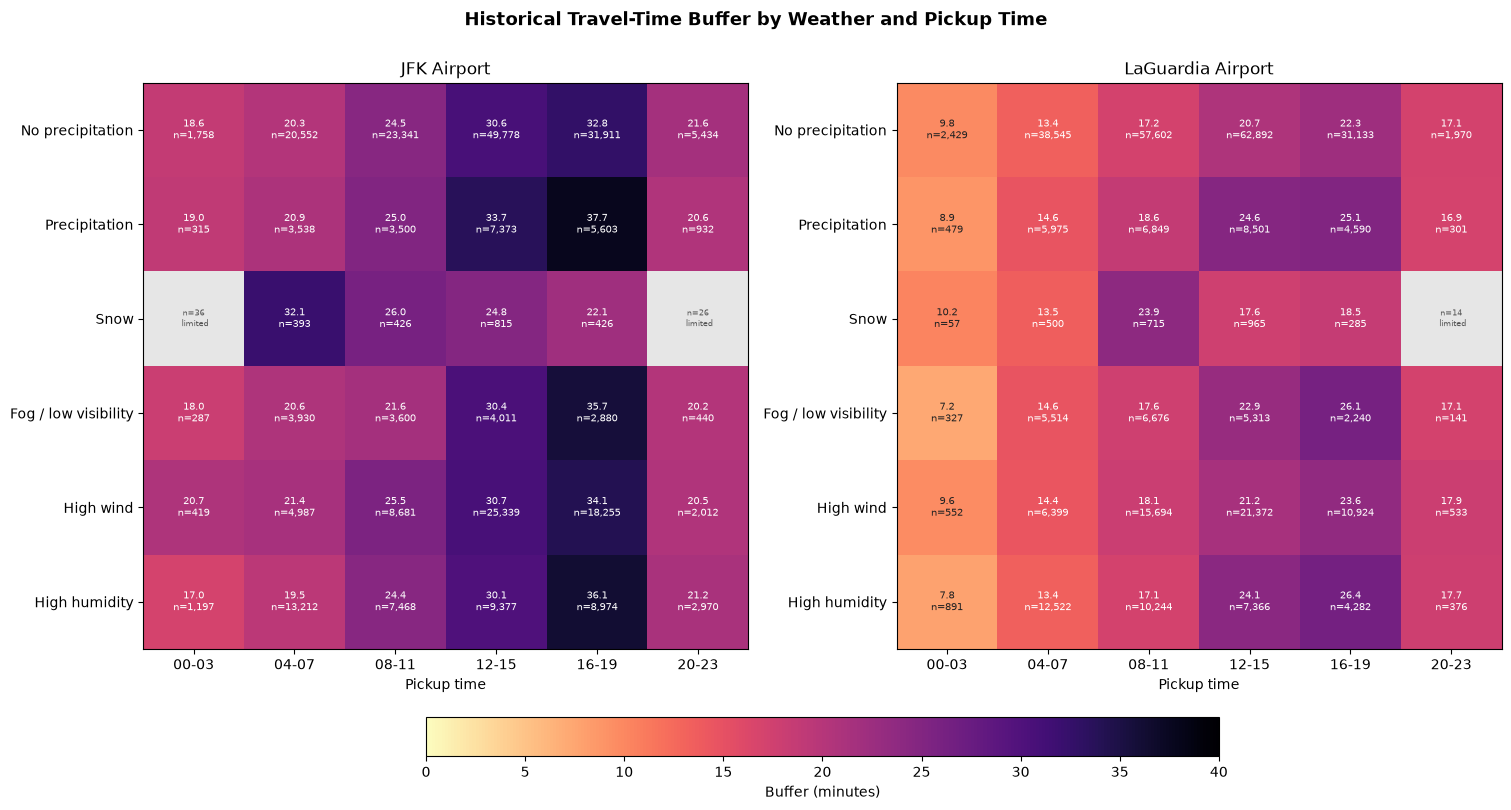

In [ ]:
weather_time_pdf = (weather_time_summary
    .select(
        "airport",
        "weather_condition",
        "time_period",
        "trip_count",
        "buffer_minutes")
    .toPandas())

weather_condition_order = ["No precipitation", "Precipitation", "Snow",
"Fog / low visibility", "High wind", "High humidity"]

buffer_max = math.ceil(weather_time_pdf["buffer_minutes"].max() / 5) * 5

buffer_norm = Normalize(vmin=0, vmax=buffer_max)

buffer_cmap = plt.get_cmap(MAP_CMAP).copy()
buffer_cmap.set_bad("#E6E6E6")

fig, axes = plt.subplots(1, 2, figsize=(15, 8), layout="constrained")

for axis, airport in zip(axes, plot_styles.keys()):
    airport_data = weather_time_pdf.loc[weather_time_pdf["airport"] == airport]

    buffer_matrix = (
        airport_data.pivot(
            index="weather_condition",
            columns="time_period",
            values="buffer_minutes"
        ).reindex(index=weather_condition_order, columns=time_period_order)
)

    count_matrix = (
        airport_data.pivot(
            index="weather_condition",
            columns="time_period",
            values="trip_count"
        ).reindex(index=weather_condition_order, columns=time_period_order)
    )

    display_matrix = buffer_matrix.mask(count_matrix < MIN_CELL_TRIPS)

    heatmap= axis.imshow(
        display_matrix.values,
        cmap=buffer_cmap,
        norm=buffer_norm,
        aspect="auto"
    )

    axis.set_xticks(range(len(time_period_order)))
    axis.set_xticklabels(time_period_order)

    axis.tick_params(axis="y", labelleft=True)
    axis.set_yticks(range(len(weather_condition_order)))
    axis.set_yticklabels(weather_condition_order)

    axis.set_xlabel("Pickup time")
    axis.set_title(airport)
    
    for row_index in range(len(weather_condition_order)):
        for column_index in range(len(time_period_order)):
            buffer_value = buffer_matrix.iloc[row_index, column_index]
            trip_count = count_matrix.iloc[row_index, column_index]
            if pd.isna(buffer_value) or pd.isna(trip_count): continue
            if trip_count < MIN_CELL_TRIPS:
                axis.text(column_index, row_index, f"n={trip_count:.0f}\n limited",
                          ha="center", va="center", fontsize=6, color="#555555")
                continue
            red, green, blue, _ = buffer_cmap(buffer_norm(buffer_value))
            luminance = (0.2126 * red + 0.7152 * green + 0.0722 * blue)
            text_colour = ("white" if luminance < 0.5 else "#222222")
            axis.text(
                column_index, row_index, f"{buffer_value:.1f}\n"
                f"n={trip_count:,.0f}", ha="center", va="center",
                fontsize=7, color=text_colour
            )
            
fig.suptitle(
    "Historical Travel-Time Buffer by Weather and Pickup Time\n",
    fontsize=13,
    fontweight="bold"
)

fig.colorbar(
    heatmap, 
    ax=axes.tolist(),
    orientation="horizontal",
    fraction=0.07,
    pad=0.04,
    label="Buffer (minutes)"
)

fig.savefig(PLOTS_DIR / "weather_time_buffer_heatmap.pdf", bbox_inches="tight")

plt.show()